In [2]:
pip install tensorflow numpy pandas matplotlib seaborn scikit-learn pillow streamlit

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from PIL import Image
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Konfigurasi visualisasi
plt.style.use("default")
sns.set_theme(style="whitegrid")

# Random seed
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Seluruh library berhasil diimpor.")
print("TensorFlow Version:", tf.__version__)

Seluruh library berhasil diimpor.
TensorFlow Version: 2.21.0


In [4]:
from pathlib import Path

# Direktori utama proyek
BASE_DIR = Path.cwd()

# Lokasi dataset ZIP
ZIP_PATH = BASE_DIR / "archive.zip"

# Direktori ekstraksi
DATASET_DIR = BASE_DIR / "dataset"

# Direktori gambar
DATA_DIR = DATASET_DIR / "processed_data"

# Direktori output
OUTPUT_DIR = BASE_DIR / "outputs"

# Direktori penyimpanan model
MODEL_DIR = BASE_DIR / "models"

# Membuat folder jika belum tersedia
DATASET_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

print("DIREKTORI PROYEK")
print("Lokasi proyek :", BASE_DIR)
print("File ZIP      :", ZIP_PATH)
print("Dataset       :", DATA_DIR)
print("Output        :", OUTPUT_DIR)
print("Model         :", MODEL_DIR)

DIREKTORI PROYEK
Lokasi proyek : c:\Praktikum big data\pengenalan_emosi_wajah
File ZIP      : c:\Praktikum big data\pengenalan_emosi_wajah\archive.zip
Dataset       : c:\Praktikum big data\pengenalan_emosi_wajah\dataset\processed_data
Output        : c:\Praktikum big data\pengenalan_emosi_wajah\outputs
Model         : c:\Praktikum big data\pengenalan_emosi_wajah\models


In [5]:
import zipfile

if not ZIP_PATH.exists():
    raise FileNotFoundError("File archive.zip tidak ditemukan!")

if not DATA_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATASET_DIR)

    print("Ekstraksi dataset berhasil.")
else:
    print("Dataset sudah tersedia. Ekstraksi dilewati.")

print("Lokasi dataset:", DATA_DIR)

Dataset sudah tersedia. Ekstraksi dilewati.
Lokasi dataset: c:\Praktikum big data\pengenalan_emosi_wajah\dataset\processed_data


In [6]:
class_names = sorted([
    folder.name
    for folder in DATA_DIR.iterdir()
    if folder.is_dir()
])

data_distribution = []

for class_name in class_names:
    class_path = DATA_DIR / class_name

    total_images = len([
        file for file in class_path.iterdir()
        if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])

    data_distribution.append({
        "Kelas Emosi": class_name,
        "Jumlah Gambar": total_images
    })

df_distribution = pd.DataFrame(data_distribution)

print("DAFTAR KELAS EMOSI")
display(df_distribution)

print("Total kelas:", len(class_names))
print("Total gambar:", df_distribution["Jumlah Gambar"].sum())

DAFTAR KELAS EMOSI


,Kelas Emosi,Jumlah Gambar
0,angry,5920
1,disgust,5920
2,fear,5920
3,happy,11398
4,neutral,8166
5,sad,6535
6,surprise,5920


Total kelas: 7
Total gambar: 49779


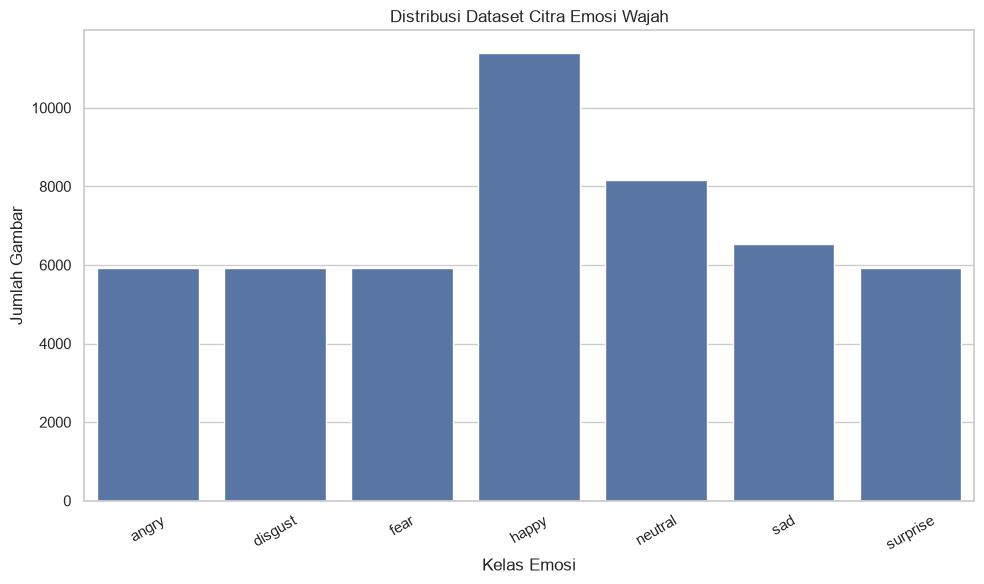

In [7]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_distribution,
    x="Kelas Emosi",
    y="Jumlah Gambar"
)

plt.title("Distribusi Dataset Citra Emosi Wajah")
plt.xlabel("Kelas Emosi")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

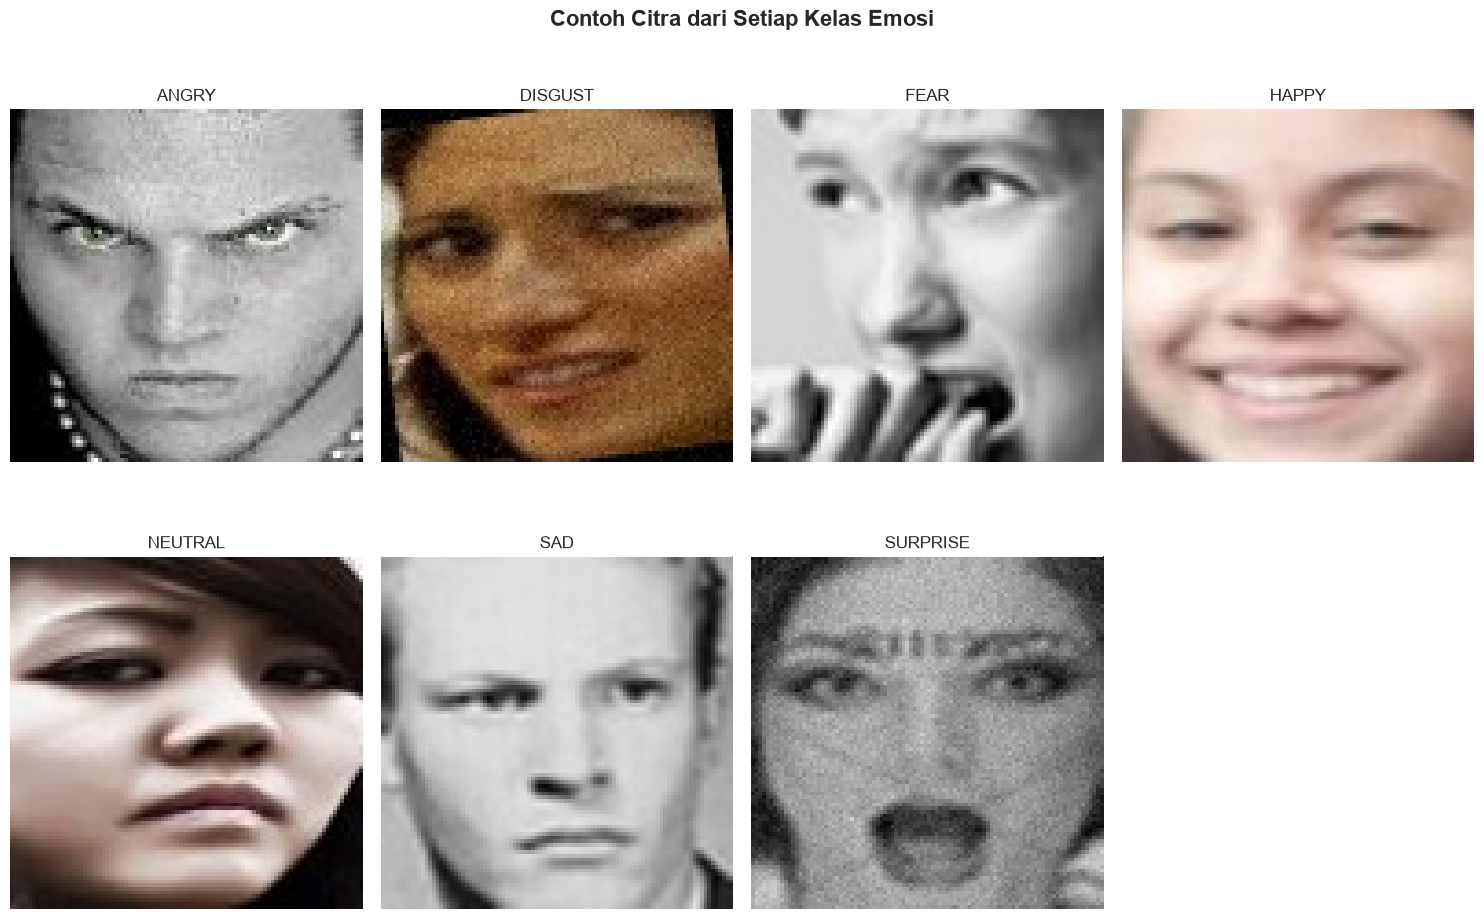

In [8]:
import random

plt.figure(figsize=(15, 10))

for i, class_name in enumerate(class_names):
    class_path = DATA_DIR / class_name

    image_files = list(class_path.glob("*.jpg"))

    # Memilih satu gambar secara acak
    sample_image = random.choice(image_files)

    # Membaca gambar
    img = Image.open(sample_image)

    # Menampilkan gambar
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(class_name.upper(), fontsize=12)
    plt.axis("off")

plt.suptitle(
    "Contoh Citra dari Setiap Kelas Emosi",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [9]:
image_properties = []

for class_name in class_names:

    class_path = DATA_DIR / class_name
    image_files = list(class_path.glob("*.jpg"))

    # Mengambil maksimal 100 gambar secara acak
    samples = random.sample(
        image_files,
        min(100, len(image_files))
    )

    for image_file in samples:

        with Image.open(image_file) as img:

            image_properties.append({
                "Kelas": class_name,
                "Lebar": img.width,
                "Tinggi": img.height,
                "Mode Warna": img.mode,
                "Format": img.format
            })

df_image_properties = pd.DataFrame(image_properties)

print("INFORMASI KARAKTERISTIK CITRA")
display(df_image_properties.head(10))

print("\nSTATISTIK RESOLUSI")
display(
    df_image_properties[
        ["Lebar", "Tinggi"]
    ].describe()
)

print("\nDISTRIBUSI MODE WARNA")
display(
    df_image_properties["Mode Warna"].value_counts()
)

print("\nDISTRIBUSI FORMAT GAMBAR")
display(
    df_image_properties["Format"].value_counts()
)

INFORMASI KARAKTERISTIK CITRA


,Kelas,Lebar,Tinggi,Mode Warna,Format
0,angry,96,96,RGB,JPEG
1,angry,96,96,RGB,JPEG
2,angry,96,96,RGB,JPEG
3,angry,96,96,RGB,JPEG
4,angry,96,96,RGB,JPEG
5,angry,96,96,RGB,JPEG
6,angry,96,96,RGB,JPEG
7,angry,96,96,RGB,JPEG
8,angry,96,96,RGB,JPEG
9,angry,96,96,RGB,JPEG



STATISTIK RESOLUSI


,Lebar,Tinggi
count,700.0,700.0
mean,96.0,96.0
std,0.0,0.0
min,96.0,96.0
25%,96.0,96.0
50%,96.0,96.0
75%,96.0,96.0
max,96.0,96.0



DISTRIBUSI MODE WARNA


Mode Warna
RGB    700
Name: count, dtype: int64


DISTRIBUSI FORMAT GAMBAR


Format
JPEG    700
Name: count, dtype: int64

In [10]:
from collections import Counter

total_checked = 0
corrupted_images = []
resolution_counter = Counter()
mode_counter = Counter()

for class_name in class_names:

    class_path = DATA_DIR / class_name

    image_files = [
        file for file in class_path.iterdir()
        if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    for image_file in image_files:

        try:
            with Image.open(image_file) as img:

                img.verify()

            with Image.open(image_file) as img:

                resolution_counter[img.size] += 1
                mode_counter[img.mode] += 1

            total_checked += 1

        except Exception:
            corrupted_images.append(str(image_file))

print("HASIL PEMERIKSAAN DATASET")
print("=" * 45)

print("Total gambar diperiksa :", total_checked)
print("Gambar rusak           :", len(corrupted_images))

print("\nDISTRIBUSI RESOLUSI")
for resolution, count in resolution_counter.items():
    print(f"{resolution}: {count:,} gambar")

print("\nDISTRIBUSI MODE WARNA")
for mode, count in mode_counter.items():
    print(f"{mode}: {count:,} gambar")

if corrupted_images:
    print("\nContoh file rusak:")
    for file in corrupted_images[:10]:
        print(file)
else:
    print("\nSeluruh gambar berhasil diperiksa.")

HASIL PEMERIKSAAN DATASET
Total gambar diperiksa : 49779
Gambar rusak           : 0

DISTRIBUSI RESOLUSI
(96, 96): 49,779 gambar

DISTRIBUSI MODE WARNA
RGB: 49,779 gambar

Seluruh gambar berhasil diperiksa.


In [11]:
image_paths = []
image_labels = []

for label, class_name in enumerate(class_names):

    class_path = DATA_DIR / class_name

    files = list(class_path.glob("*.jpg"))

    for file in files:
        image_paths.append(str(file))
        image_labels.append(label)

image_paths = np.array(image_paths)
image_labels = np.array(image_labels)

print("Total gambar :", len(image_paths))
print("Total label  :", len(image_labels))
print("\nPemetaan Label:")

for i, name in enumerate(class_names):
    print(f"{i} = {name}")

Total gambar : 49779
Total label  : 49779

Pemetaan Label:
0 = angry
1 = disgust
2 = fear
3 = happy
4 = neutral
5 = sad
6 = surprise


In [12]:
from sklearn.model_selection import train_test_split

# Membagi 80% training dan 20% sementara
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    image_labels,
    test_size=0.20,
    random_state=SEED,
    stratify=image_labels
)

# Membagi 20% sementara menjadi validation dan testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("HASIL PEMBAGIAN DATASET")
print("=" * 40)

print(f"Training   : {len(X_train):,} gambar")
print(f"Validation : {len(X_val):,} gambar")
print(f"Testing    : {len(X_test):,} gambar")

print("=" * 40)
print(f"Total      : {len(X_train) + len(X_val) + len(X_test):,} gambar")

HASIL PEMBAGIAN DATASET
Training   : 39,823 gambar
Validation : 4,978 gambar
Testing    : 4,978 gambar
Total      : 49,779 gambar


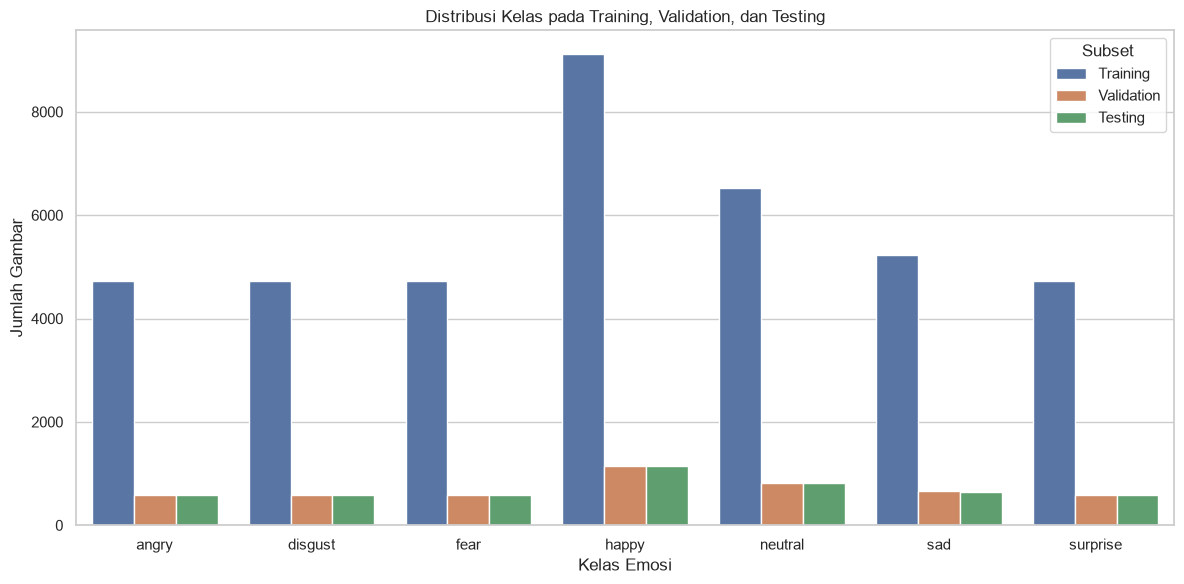

In [13]:
split_distribution = []

for split_name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:

    counts = Counter(labels)

    for i, class_name in enumerate(class_names):

        split_distribution.append({
            "Kelas": class_name,
            "Subset": split_name,
            "Jumlah": counts[i]
        })

df_split = pd.DataFrame(split_distribution)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_split,
    x="Kelas",
    y="Jumlah",
    hue="Subset"
)

plt.title("Distribusi Kelas pada Training, Validation, dan Testing")
plt.xlabel("Kelas Emosi")
plt.ylabel("Jumlah Gambar")
plt.tight_layout()
plt.show()

In [14]:
IMG_SIZE = (96, 96)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_image(image_path, label):

    # Membaca file gambar
    image = tf.io.read_file(image_path)

    # Decode gambar JPEG menjadi RGB
    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    # Resize gambar
    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    # Normalisasi piksel menjadi 0-1
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


def create_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED
        )

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# Membuat dataset TensorFlow
train_ds = create_dataset(
    X_train, y_train, training=True
)

val_ds = create_dataset(
    X_val, y_val
)

test_ds = create_dataset(
    X_test, y_test
)

print("Pipeline preprocessing berhasil dibuat.")
print("Training batches  :", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches   :", len(test_ds))

Pipeline preprocessing berhasil dibuat.
Training batches  : 1245
Validation batches: 156
Testing batches   : 156


Bentuk tensor gambar : (32, 96, 96, 3)
Bentuk tensor label  : (32,)
Nilai piksel minimum : 0.0
Nilai piksel maksimum: 1.0


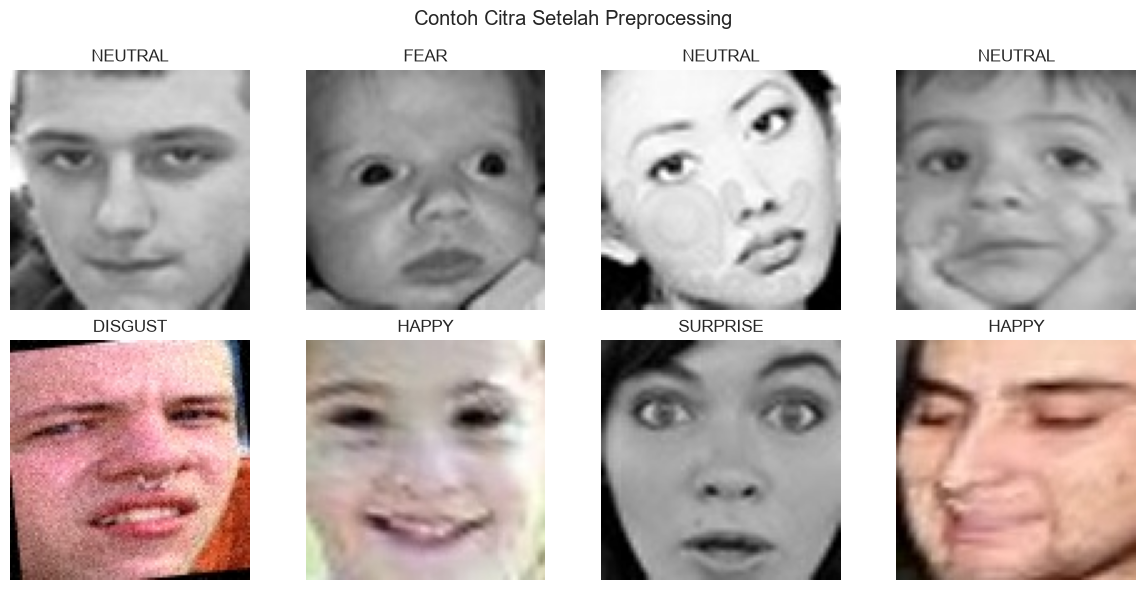

In [15]:
images, labels = next(iter(train_ds))

print("Bentuk tensor gambar :", images.shape)
print("Bentuk tensor label  :", labels.shape)
print("Nilai piksel minimum :", tf.reduce_min(images).numpy())
print("Nilai piksel maksimum:", tf.reduce_max(images).numpy())

# Visualisasi hasil preprocessing
plt.figure(figsize=(12, 6))

for i in range(8):

    plt.subplot(2, 4, i + 1)

    plt.imshow(images[i].numpy())

    label = int(labels[i].numpy())

    plt.title(class_names[label].upper())
    plt.axis("off")

plt.suptitle("Contoh Citra Setelah Preprocessing")
plt.tight_layout()
plt.show()

In [16]:
from tensorflow.keras import layers, models

# Data augmentation
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
], name="data_augmentation")


# Membangun model CNN
model = models.Sequential([

    layers.Input(shape=(96, 96, 3)),

    # Data augmentation
    data_augmentation,

    # Convolution Block 1
    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Feature extraction
    layers.GlobalAveragePooling2D(),

    # Fully connected layer
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Output layer
    layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

# Menampilkan arsitektur model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,559 (435.78 KB)

 Trainable params: 111,111 (434.03 KB)

 Non-trainable params: 448 (1.75 KB)

In [17]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Model CNN berhasil dikompilasi.")
print("Optimizer : Adam")
print("Loss      : Sparse Categorical Crossentropy")
print("Metric    : Accuracy")

Model CNN berhasil dikompilasi.
Optimizer : Adam
Loss      : Sparse Categorical Crossentropy
Metric    : Accuracy


In [18]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        np.unique(y_train),
        class_weights
    )
}

print("CLASS WEIGHT")
for class_id, weight in class_weight_dict.items():
    print(
        f"{class_names[class_id]}: {weight:.4f}"
    )

CLASS WEIGHT
angry: 1.2012
disgust: 1.2012
fear: 1.2012
happy: 0.6239
neutral: 0.8708
sad: 1.0882
surprise: 1.2012


In [19]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

EPOCHS = 30

os.makedirs(MODEL_DIR, exist_ok=True)

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_emotion_cnn.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("Konfigurasi training berhasil dibuat.")
print("Maksimal epoch:", EPOCHS)

Konfigurasi training berhasil dibuat.
Maksimal epoch: 30


In [20]:
import time

print("MEMULAI TRAINING MODEL CNN")
print("=" * 50)

start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

end_time = time.time()

training_time = end_time - start_time

print("\nTRAINING SELESAI")
print("=" * 50)

print(f"Total epoch       : {len(history.history['loss'])}")
print(f"Waktu training    : {training_time / 60:.2f} menit")
print(f"Akurasi training  : {history.history['accuracy'][-1] * 100:.2f}%")
print(f"Akurasi validation: {history.history['val_accuracy'][-1] * 100:.2f}%")

MEMULAI TRAINING MODEL CNN
Epoch 1/30


c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1245/1245 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step - accuracy: 0.2739 - loss: 1.7543
Epoch 1: val_loss improved from None to 1.85849, saving model to c:\Praktikum big data\pengenalan_emosi_wajah\models\best_emotion_cnn.keras

Epoch 1: finished saving model to c:\Praktikum big data\pengenalan_emosi_wajah\models\best_emotion_cnn.keras
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 377s 299ms/step - accuracy: 0.2739 - loss: 1.7543 - val_accuracy: 0.2587 - val_loss: 1.8585 - learning_rate: 0.0010
Epoch 2/30
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step - accuracy: 0.3339 - loss: 1.6312
Epoch 2: val_loss did not improve from 1.85849
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 374s 300ms/step - accuracy: 0.3339 - loss: 1.6312 - val_accuracy: 0.2170 - val_loss: 5.0568 - learning_rate: 0.0010
Epoch 3/30
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - accuracy: 0.3976 - loss: 1.5179
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 3: val_loss did not improve from 1.85849
1245/1245 ━━━━━━━━━━━━━━━━

In [21]:

from tensorflow.keras.models import load_model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Memuat model CNN terbaik
BEST_MODEL_PATH = MODEL_DIR / "best_emotion_cnn.keras"

best_model = load_model(BEST_MODEL_PATH)

print("Model terbaik berhasil dimuat.")
print("Lokasi:", BEST_MODEL_PATH)

# 2. Evaluasi model pada data testing
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

# 3. Menghasilkan prediksi
y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = best_model.predict(
        images,
        verbose=0
    )

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 4. Menghitung metrik evaluasi
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

# 5. Menampilkan hasil evaluasi
print("\n" + "=" * 55)
print("HASIL EVALUASI MODEL CNN")
print("=" * 55)

print(f"Test Loss  : {test_loss:.4f}")
print(f"Accuracy   : {accuracy * 100:.2f}%")
print(f"Precision  : {precision * 100:.2f}%")
print(f"Recall     : {recall * 100:.2f}%")
print(f"F1-Score   : {f1 * 100:.2f}%")

print("\nCLASSIFICATION REPORT")
print("=" * 55)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# 6. Menyimpan hasil evaluasi
evaluation_results = pd.DataFrame({
    "Metrik": [
        "Test Loss",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Nilai": [
        test_loss,
        accuracy,
        precision,
        recall,
        f1
    ]
})

display(evaluation_results)

evaluation_results.to_csv(
    OUTPUT_DIR / "evaluation_results.csv",
    index=False
)

print("\nHasil evaluasi berhasil disimpan.")


Model terbaik berhasil dimuat.
Lokasi: c:\Praktikum big data\pengenalan_emosi_wajah\models\best_emotion_cnn.keras
156/156 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - accuracy: 0.5510 - loss: 1.1629

HASIL EVALUASI MODEL CNN
Test Loss  : 1.1629
Accuracy   : 55.10%
Precision  : 58.70%
Recall     : 55.10%
F1-Score   : 55.96%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       angry     0.3829    0.4527    0.4149       592
     disgust     0.7340    0.5828    0.6497       592
        fear     0.3604    0.2770    0.3133       592
       happy     0.8661    0.6412    0.7369      1140
     neutral     0.5458    0.5398    0.5428       817
         sad     0.3593    0.5789    0.4434       653
    surprise     0.6410    0.7027    0.6704       592

    accuracy                         0.5510      4978
   macro avg     0.5556    0.5393    0.5388      4978
weighted avg     0.5870    0.5510    0.5596      4978



,Metrik,Nilai
0,Test Loss,1.162908
1,Accuracy,0.551025
2,Precision,0.586975
3,Recall,0.551025
4,F1-Score,0.559588



Hasil evaluasi berhasil disimpan.


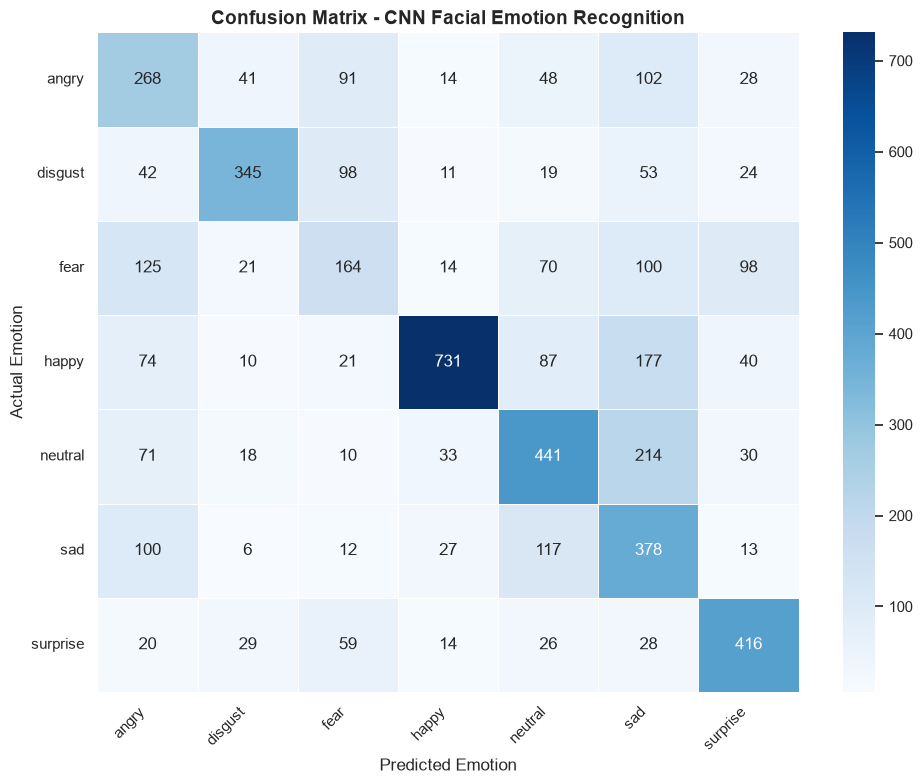

Confusion Matrix berhasil dibuat.
Lokasi penyimpanan: c:\Praktikum big data\pengenalan_emosi_wajah\outputs\confusion_matrix.png

RINGKASAN CONFUSION MATRIX
Total data testing : 4978
Prediksi benar     : 2743
Prediksi salah     : 2235
Persentase benar   : 55.10%


In [22]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Membuat confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

# 2. Visualisasi confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    cbar=True
)

plt.title(
    "Confusion Matrix - CNN Facial Emotion Recognition",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Emotion", fontsize=12)
plt.ylabel("Actual Emotion", fontsize=12)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

# 3. Menyimpan visualisasi
cm_path = OUTPUT_DIR / "confusion_matrix.png"

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion Matrix berhasil dibuat.")
print("Lokasi penyimpanan:", cm_path)

# 4. Menampilkan jumlah prediksi benar
correct_predictions = np.trace(cm)
total_predictions = np.sum(cm)

print("\nRINGKASAN CONFUSION MATRIX")
print("=" * 45)
print("Total data testing :", total_predictions)
print("Prediksi benar     :", correct_predictions)
print("Prediksi salah     :", total_predictions - correct_predictions)
print(
    "Persentase benar   :",
    f"{correct_predictions / total_predictions * 100:.2f}%"
)


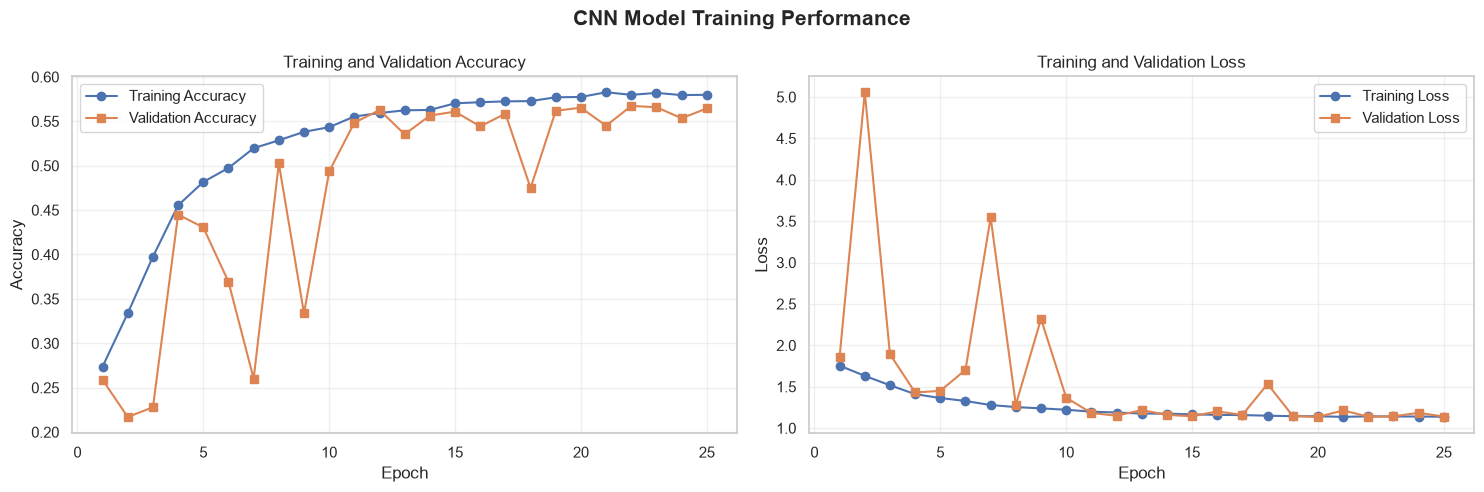

Grafik training berhasil dibuat.
Lokasi penyimpanan: c:\Praktikum big data\pengenalan_emosi_wajah\outputs\training_history.png


In [23]:
# Mengambil riwayat training
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(acc) + 1)

# Membuat dua grafik
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Grafik Accuracy
ax[0].plot(
    epochs_range,
    acc,
    marker="o",
    label="Training Accuracy"
)

ax[0].plot(
    epochs_range,
    val_acc,
    marker="s",
    label="Validation Accuracy"
)

ax[0].set_title("Training and Validation Accuracy")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Accuracy")
ax[0].legend()
ax[0].grid(alpha=0.3)

# Grafik Loss
ax[1].plot(
    epochs_range,
    loss,
    marker="o",
    label="Training Loss"
)

ax[1].plot(
    epochs_range,
    val_loss,
    marker="s",
    label="Validation Loss"
)

ax[1].set_title("Training and Validation Loss")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Loss")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.suptitle(
    "CNN Model Training Performance",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

# Menyimpan grafik
history_path = OUTPUT_DIR / "training_history.png"

plt.savefig(
    history_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grafik training berhasil dibuat.")
print("Lokasi penyimpanan:", history_path)


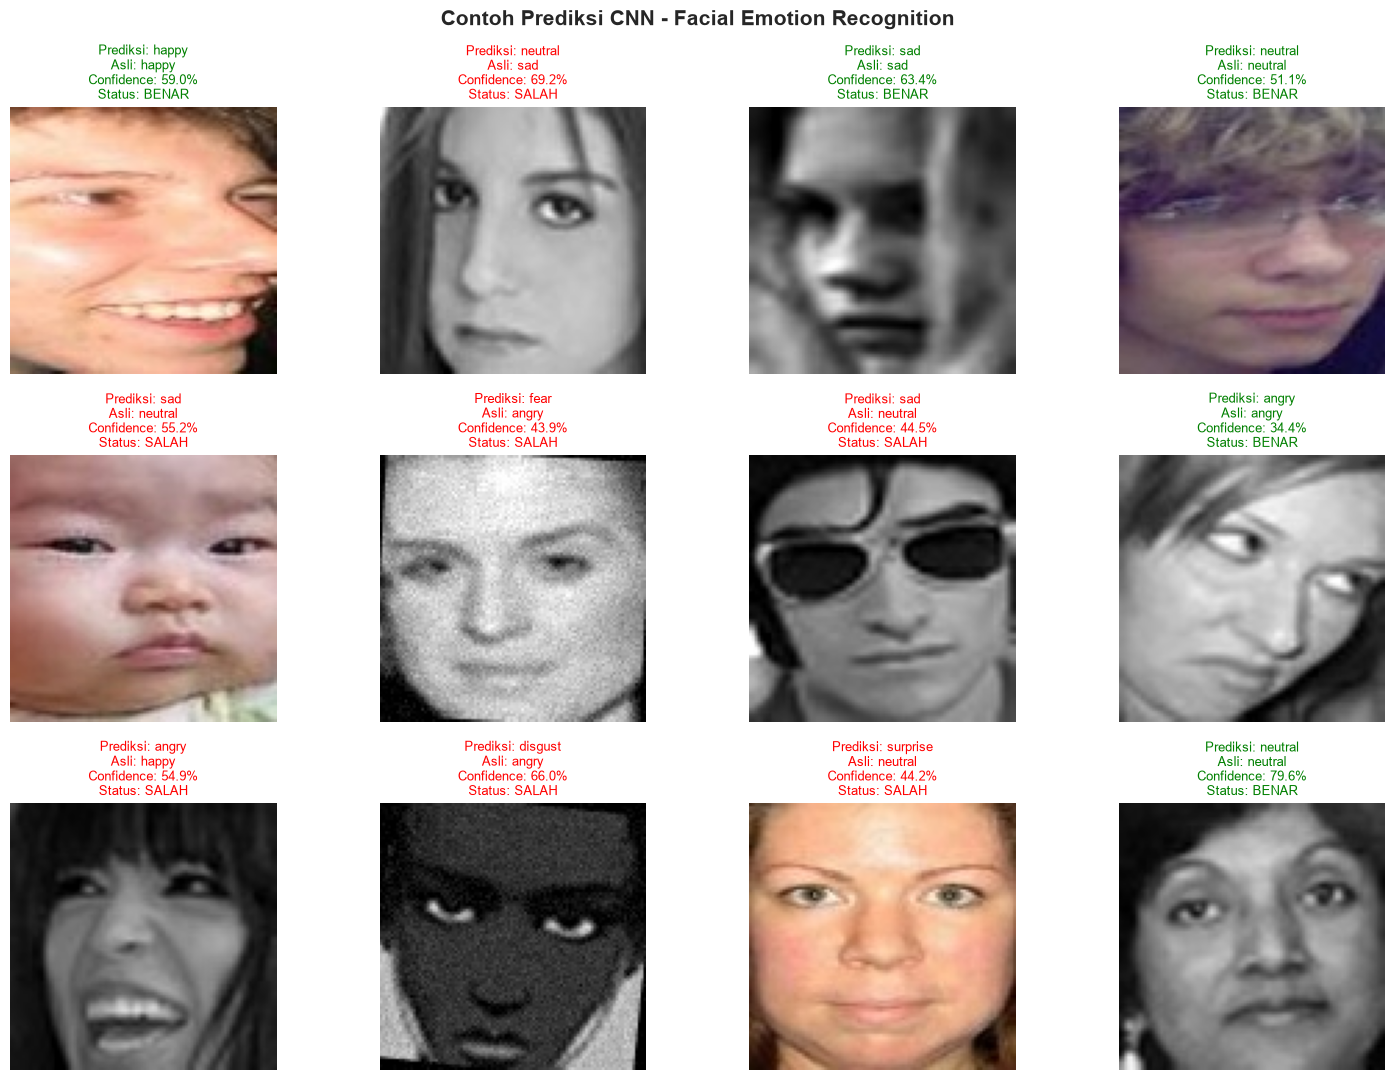

Visualisasi contoh prediksi berhasil dibuat.
Lokasi penyimpanan: c:\Praktikum big data\pengenalan_emosi_wajah\outputs\sample_predictions.png

RINGKASAN PREDIKSI SAMPEL
Jumlah gambar : 12
Prediksi benar: 5
Prediksi salah: 7


In [24]:
# Mengumpulkan contoh gambar dan hasil prediksi
sample_images = []
sample_true = []
sample_pred = []
sample_confidence = []

# Mengambil maksimal 12 gambar dari data testing
for images, labels in test_ds:

    predictions = best_model.predict(
        images,
        verbose=0
    )

    images_np = images.numpy()
    labels_np = labels.numpy()

    for i in range(len(images_np)):

        # Mengambil label sebenarnya
        if labels_np.ndim > 1 and labels_np.shape[-1] > 1:
            actual = int(np.argmax(labels_np[i]))
        else:
            actual = int(np.asarray(labels_np[i]).reshape(-1)[0])

        # Mengambil hasil prediksi
        predicted = int(np.argmax(predictions[i]))
        confidence = float(predictions[i][predicted]) * 100

        sample_images.append(images_np[i])
        sample_true.append(actual)
        sample_pred.append(predicted)
        sample_confidence.append(confidence)

        if len(sample_images) >= 12:
            break

    if len(sample_images) >= 12:
        break


# Membuat visualisasi 12 gambar
fig, axes = plt.subplots(3, 4, figsize=(15, 11))

axes = axes.flatten()

for i, ax in enumerate(axes):

    img = sample_images[i].copy()

    # Menyesuaikan skala gambar untuk visualisasi
    if img.min() < 0:
        img = (img + 1.0) / 2.0
    elif img.max() > 1:
        img = img / 255.0

    img = np.clip(img, 0, 1)

    actual_name = class_names[sample_true[i]]
    predicted_name = class_names[sample_pred[i]]

    correct = sample_true[i] == sample_pred[i]

    # Menampilkan gambar
    if img.ndim == 3 and img.shape[-1] == 1:
        ax.imshow(img.squeeze(), cmap="gray")
    elif img.ndim == 2:
        ax.imshow(img, cmap="gray")
    else:
        ax.imshow(img)

    # Judul prediksi
    status = "BENAR" if correct else "SALAH"

    ax.set_title(
        f"Prediksi: {predicted_name}\n"
        f"Asli: {actual_name}\n"
        f"Confidence: {sample_confidence[i]:.1f}%\n"
        f"Status: {status}",
        color="green" if correct else "red",
        fontsize=9
    )

    ax.axis("off")


plt.suptitle(
    "Contoh Prediksi CNN - Facial Emotion Recognition",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

# Menyimpan visualisasi
prediction_path = OUTPUT_DIR / "sample_predictions.png"

plt.savefig(
    prediction_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Visualisasi contoh prediksi berhasil dibuat.")
print("Lokasi penyimpanan:", prediction_path)

# Ringkasan hasil prediksi sampel
correct_samples = sum(
    np.array(sample_true) == np.array(sample_pred)
)

print("\nRINGKASAN PREDIKSI SAMPEL")
print("=" * 45)
print("Jumlah gambar :", len(sample_images))
print("Prediksi benar:", correct_samples)
print("Prediksi salah:", len(sample_images) - correct_samples)


In [25]:
import json
import pandas as pd
import numpy as np

# 1. Memastikan direktori tersedia
MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Menyimpan nama kelas emosi
class_names_path = MODEL_DIR / "class_names.json"

with open(class_names_path, "w", encoding="utf-8") as f:
    json.dump(
        class_names,
        f,
        indent=4,
        ensure_ascii=False
    )

# 3. Menyimpan konfigurasi preprocessing
model_config = {
    "model_name": "CNN Facial Emotion Recognition",
    "image_size": list(IMG_SIZE),
    "color_mode": "RGB",
    "normalization": "pixel_value_divided_by_255",
    "number_of_classes": len(class_names),
    "class_names": class_names,
    "batch_size": BATCH_SIZE
}

config_path = MODEL_DIR / "model_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(
        model_config,
        f,
        indent=4,
        ensure_ascii=False
    )

# 4. Menyimpan training history
history_df = pd.DataFrame(history.history)

history_df.insert(
    0,
    "epoch",
    range(1, len(history_df) + 1)
)

history_path = OUTPUT_DIR / "training_history.csv"

history_df.to_csv(
    history_path,
    index=False
)

# 5. Menyimpan classification report
report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_path = OUTPUT_DIR / "classification_report.csv"

report_df.to_csv(report_path)

# 6. Menyimpan distribusi dataset
distribution_path = OUTPUT_DIR / "dataset_distribution.csv"

df_distribution.to_csv(
    distribution_path,
    index=False
)

# 7. Memeriksa keberadaan model terbaik
best_model_path = MODEL_DIR / "best_emotion_cnn.keras"

if not best_model_path.exists():
    raise FileNotFoundError(
        "File model terbaik tidak ditemukan!"
    )

# 8. Menampilkan ringkasan aset
print("=" * 55)
print("PENYIMPANAN ASET MODEL BERHASIL")
print("=" * 55)

print("\nMODEL:")
print(best_model_path)

print("\nASET PENDUKUNG:")
print(class_names_path)
print(config_path)
print(history_path)
print(report_path)
print(distribution_path)

print("\nKONFIGURASI MODEL")
print("Ukuran gambar :", IMG_SIZE)
print("Jumlah kelas  :", len(class_names))
print("Nama kelas    :", class_names)
print("Epoch training:", len(history_df))

print("\nSemua aset siap digunakan untuk aplikasi Streamlit.")


PENYIMPANAN ASET MODEL BERHASIL

MODEL:
c:\Praktikum big data\pengenalan_emosi_wajah\models\best_emotion_cnn.keras

ASET PENDUKUNG:
c:\Praktikum big data\pengenalan_emosi_wajah\models\class_names.json
c:\Praktikum big data\pengenalan_emosi_wajah\models\model_config.json
c:\Praktikum big data\pengenalan_emosi_wajah\outputs\training_history.csv
c:\Praktikum big data\pengenalan_emosi_wajah\outputs\classification_report.csv
c:\Praktikum big data\pengenalan_emosi_wajah\outputs\dataset_distribution.csv

KONFIGURASI MODEL
Ukuran gambar : (96, 96)
Jumlah kelas  : 7
Nama kelas    : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Epoch training: 25

Semua aset siap digunakan untuk aplikasi Streamlit.
